In [1]:
from ase.io import read
from ase.build import make_supercell
from matplotlib import rc
rc("text", usetex=True)
import matplotlib.pylab as pylab
params = {"legend.fontsize": "14", "axes.labelsize": 20, "axes.titlesize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16}
pylab.rcParams.update(params)
import numpy as np
import glob


try:
    from tqdm import tqdm as _tqdm

    _TQDM_AVAILABLE = True
except ImportError:
    _TQDM_AVAILABLE = False


def _progress(iterable, **kwargs):
    """Wrap an iterable with tqdm if available, else return as-is."""
    if _TQDM_AVAILABLE:
        return _tqdm(iterable, **kwargs)
    return iterable

In [2]:
# load the molecular dynamics trajectory
traj_directory = "/Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/"
all_traj_files = glob.glob(traj_directory + "nve_md_*.traj")
traj = []
for i in range(len(all_traj_files)):
    print(f"Loading trajectory file {i+1}/{len(all_traj_files)}: {all_traj_files[i]}")
    traj_name = traj_directory + f"nve_md_{i+1}.traj"
    traj += read(traj_name, index=":")
print("loaded", len(traj), "frames")

# loop through the trajectory and update each frame's positions to be the wrapped positions, and compute the average structure
averaged_structure = traj[0].copy()
averaged_structure.positions[:] = 0.0

coms_all_frames = []
all_masses = np.array([atom.mass for atom in traj[0]], dtype=float)
total_mass = all_masses.sum()

for frame in _progress(traj, desc="Computing averaged structure", leave=False):
    # Vectorized wrapping (fractional -> wrapped Cartesian) handled by ASE.
    wrapped_positions = frame.get_positions(wrap=True)
    frame.positions[:] = wrapped_positions

    averaged_structure.positions += wrapped_positions
    coms_all_frames.append(np.average(wrapped_positions, axis=0, weights=all_masses))

averaged_structure.positions /= len(traj)
print("computed averaged structure, and all centers of masses")

# compute the COM for the averaged structure
center_of_mass_averaged_structure = np.zeros(3)
for atom in averaged_structure:
    center_of_mass_averaged_structure += averaged_structure.positions[atom.index] * atom.mass
center_of_mass_averaged_structure /= total_mass
print("computed center of mass for the averaged structure")

Loading trajectory file 1/52: /Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/nve_md_32.traj
Loading trajectory file 2/52: /Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/nve_md_24.traj
Loading trajectory file 3/52: /Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/nve_md_49.traj
Loading trajectory file 4/52: /Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/nve_md_28.traj
Loading trajectory file 5/52: /Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/nve_md_12.traj
Loading trajectory file 6/52: /Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/nve_md_

computed averaged structure, and all centers of masses
computed center of mass for the averaged structure


Computing the mass-weighted atomic displacements. For atom $i$, its time-dependent displacement is $\sqrt{m_i}\Delta\mathbf{r}_i(t)=\sqrt{m_i}\left(\mathbf{r}_i(t)-\langle\mathbf{r}_i\rangle_t\right)$, which is the difference between its instantaneous position the averaged atomic position across the entire trajectory, taking into account the periodic boundary condition. With this definition, $\Delta\mathbf{r}$ essentially captures the fluctuation of atomic positions across the entire simulation trajectory.

In [3]:
# now loop through the trajectory, and for each frame, calculate the displacement of each atom from its position in the averaged structure, taking into account the periodic boundary conditions, and normalise the displacement by the square root of the mass of each atom.
atomic_displacements = []

averaged_positions = averaged_structure.positions

# =====================================================
# pay attention to the normalisation factor, not using the inverse of the square root of the mass, but the square root of the mass itself, as per the definition of mass-weighted displacements in essential dynamics.
# =====================================================

sqrt_masses = np.sqrt(all_masses)

for frame_index, frame in _progress(enumerate(traj), total=len(traj), desc="Compute mass-normalized displacements", leave=False):
    drift = coms_all_frames[frame_index] - center_of_mass_averaged_structure

    # Vectorized displacement for all atoms in this frame.
    delta_r = frame.positions - drift - averaged_positions

    # Apply periodic boundary conditions with minimum-image convention.
    cell_diag = frame.cell.diagonal()
    delta_r -= np.round(delta_r / cell_diag) * cell_diag

    # Mass-normalize and flatten to shape (3N,).
    atomic_displacements.append((delta_r * sqrt_masses[:, None]).reshape(-1))

**Covariance Matrix Computation**

Computing the covariant matrix $\mathbf{C}$ for the displacements, in which the matrix element $C_{i\alpha,j\beta}=\langle\sqrt{m_i m_j}\Delta r_{i\alpha} \Delta r_{j\beta}\rangle$, where the Greek subscript denotes Cartesian direction.

In [4]:
atomic_displacements = np.asarray(atomic_displacements, dtype=float)

# Compute covariance in one shot: C = X^T X / n_frames
n_frames = atomic_displacements.shape[0]
covariance_matrix = (atomic_displacements.T @ atomic_displacements) / n_frames

np.save(traj_directory + "covariance_matrix.npy", covariance_matrix)

**Eigenvalue analysis**

Based on the computed covariance matrix $\mathbf{C}$, solve the eigenvalue problem of $\mathbf{C}\mathbf{v}_{k}=\lambda_k\mathbf{v}_k$. 

Plotting the eigenvalue spectrum $\{\lambda_k\}$ in descending order for MD conducted at different temperatures for an inspection.

In [ ]:
from matplotlib import pyplot as plt
traj_directory = "/Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/"

covariance_matrix_200K = np.load(traj_directory + "200_K/covariance_matrix.npy")
covariance_matrix_300K = np.load(traj_directory + "300_K/covariance_matrix.npy")
covariance_matrix_400K = np.load(traj_directory + "400_K/covariance_matrix.npy")
covariance_matrix_500K = np.load(traj_directory + "500_K/covariance_matrix.npy")
covariance_matrix_600K = np.load(traj_directory + "600_K/covariance_matrix.npy")
covariance_matrix_700K = np.load(traj_directory + "700_K_rerun/covariance_matrix.npy")
covariance_matrix_800K = np.load(traj_directory + "800_K/covariance_matrix.npy")


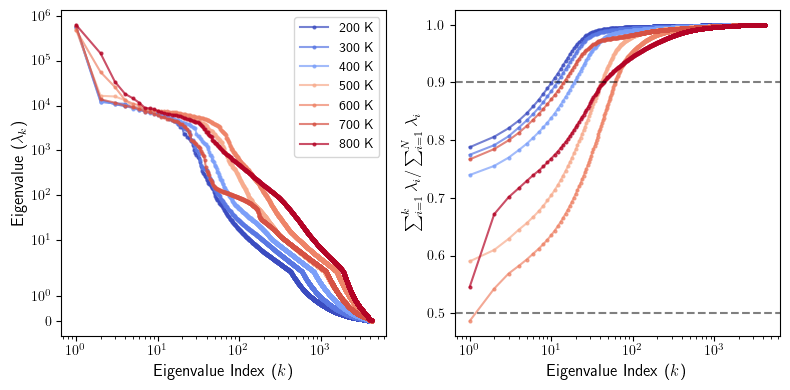

In [3]:
eigenvalues_200K, eigenvectors_200K = np.linalg.eigh(covariance_matrix_200K)
eigenvalues_300K, eigenvectors_300K = np.linalg.eigh(covariance_matrix_300K)
eigenvalues_400K, eigenvectors_400K = np.linalg.eigh(covariance_matrix_400K)
eigenvalues_500K, eigenvectors_500K = np.linalg.eigh(covariance_matrix_500K)
eigenvalues_600K, eigenvectors_600K = np.linalg.eigh(covariance_matrix_600K)
eigenvalues_700K, eigenvectors_700K = np.linalg.eigh(covariance_matrix_700K)
eigenvalues_800K, eigenvectors_800K = np.linalg.eigh(covariance_matrix_800K)

#sort the eigenvectors according to descending order of eigenvalues
eigenvectors_200K = eigenvectors_200K[:, np.argsort(eigenvalues_200K)[::-1]]
eigenvectors_300K = eigenvectors_300K[:, np.argsort(eigenvalues_300K)[::-1]]
eigenvectors_400K = eigenvectors_400K[:, np.argsort(eigenvalues_400K)[::-1]]
eigenvectors_500K = eigenvectors_500K[:, np.argsort(eigenvalues_500K)[::-1]]
eigenvectors_600K = eigenvectors_600K[:, np.argsort(eigenvalues_600K)[::-1]]
eigenvectors_700K = eigenvectors_700K[:, np.argsort(eigenvalues_700K)[::-1]]
eigenvectors_800K = eigenvectors_800K[:, np.argsort(eigenvalues_800K)[::-1]]

#pick a color from the matplotlib colormap for each temperature
colors = plt.cm.coolwarm(np.linspace(0, 1, 11))
color_200K = colors[0]
color_300K = colors[1]
color_400K = colors[2]
color_500K = colors[7]
color_600K = colors[8]
color_700K = colors[9]
color_800K = colors[10]

fig,ax = plt.subplots(1,2, figsize=(8,4))
ax[0].plot([i+1 for i in range(len(eigenvalues_200K))], np.sort(eigenvalues_200K, axis=None)[::-1],'o-', c=color_200K, label='200 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_300K))], np.sort(eigenvalues_300K, axis=None)[::-1],'o-', c=color_300K, label='300 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_400K))], np.sort(eigenvalues_400K, axis=None)[::-1],'o-', c=color_400K, label='400 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_500K))], np.sort(eigenvalues_500K, axis=None)[::-1],'o-', c=color_500K, label='500 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_600K))], np.sort(eigenvalues_600K, axis=None)[::-1],'o-', c=color_600K, label='600 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_700K))], np.sort(eigenvalues_700K, axis=None)[::-1],'o-', c=color_700K, label='700 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_800K))], np.sort(eigenvalues_800K, axis=None)[::-1],'o-', c=color_800K, label='800 K',alpha=0.7,markersize=2)

ax[0].set_yscale("symlog")
ax[0].set_xscale("log")
ax[0].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[0].set_ylabel('Eigenvalue ($\\lambda_k$)', fontsize=12)
ax[0].tick_params(axis='both', which='both', labelsize=10)
ax[0].legend(fontsize=10)

_eigenvalues_200K = np.sort(eigenvalues_200K, axis=None)[::-1]
_eigenvalues_600K = np.sort(eigenvalues_600K, axis=None)[::-1]
_eigenvalues_300K = np.sort(eigenvalues_300K, axis=None)[::-1]
_eigenvalues_500K = np.sort(eigenvalues_500K, axis=None)[::-1]
_eigenvalues_400K = np.sort(eigenvalues_400K, axis=None)[::-1]
_eigenvalues_700K = np.sort(eigenvalues_700K, axis=None)[::-1]
_eigenvalues_800K = np.sort(eigenvalues_800K, axis=None)[::-1]

ax[1].plot([i+1 for i in range(len(eigenvalues_200K))], [np.sum(_eigenvalues_200K[:i+1])/np.sum(eigenvalues_200K) for i in range(len(eigenvalues_200K))],'-o', c=color_200K, label='200 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_300K))], [np.sum(_eigenvalues_300K[:i+1])/np.sum(eigenvalues_300K) for i in range(len(eigenvalues_300K))],'-o', c=color_300K, label='300 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_400K))], [np.sum(_eigenvalues_400K[:i+1])/np.sum(eigenvalues_400K) for i in range(len(eigenvalues_400K))],'-o', c=color_400K, label='400 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_500K))], [np.sum(_eigenvalues_500K[:i+1])/np.sum(eigenvalues_500K) for i in range(len(eigenvalues_500K))],'-o', c=color_500K, label='500 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_600K))], [np.sum(_eigenvalues_600K[:i+1])/np.sum(eigenvalues_600K) for i in range(len(eigenvalues_600K))],'-o', c=color_600K, label='600 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_700K))], [np.sum(_eigenvalues_700K[:i+1])/np.sum(eigenvalues_700K) for i in range(len(eigenvalues_700K))],'-o', c=color_700K, label='700 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_800K))], [np.sum(_eigenvalues_800K[:i+1])/np.sum(eigenvalues_800K) for i in range(len(eigenvalues_800K))],'-o', c=color_800K, label='800 K',alpha=0.7,markersize=2)
ax[1].set_xscale("log")
#ax[1].set_yscale("log")
ax[1].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[1].set_ylabel('$\\sum_{i=1}^k \\lambda_i / \\sum_{i=1}^N \\lambda_i$', fontsize=12)
ax[1].tick_params(axis='both', which='both', labelsize=10)
#ax[1].legend()
ax[1].axhline(0.9, c='k', ls='--', alpha=0.5)
ax[1].axhline(0.5, c='k', ls='--', alpha=0.5)
plt.tight_layout()
plt.show()

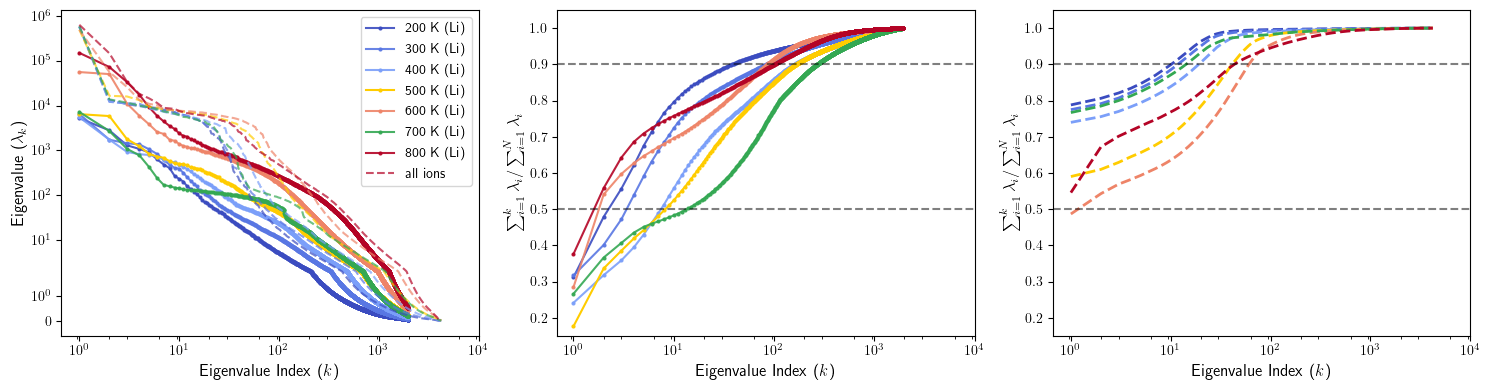

In [6]:
# repeat the above analysis but for particular sublattice only
element = "Li"
input_atom_order = read(
    "/Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/600_K/CONTCAR"
).get_chemical_symbols()
element_indices = [i for i, symbol in enumerate(input_atom_order) if symbol == element]
element_indices = list(np.array([[3 * i, 3 * i + 1, 3 * i + 2] for i in element_indices]).reshape(-1))
framework_indices = [i for i, symbol in enumerate(input_atom_order) if symbol != element]
framework_indices = list(np.array([[3 * i, 3 * i + 1, 3 * i + 2] for i in framework_indices]).reshape(-1))

# pick a color from the matplotlib colormap for each temperature
colors = plt.cm.coolwarm(np.linspace(0, 1, 11))
color_200K = colors[0]
color_300K = colors[1]
color_400K = colors[2]
color_500K = "#FFCC00"
color_600K = colors[8]
color_700K = "#34A853"
color_800K = colors[10]

# now in the covariance matrix, only keep the rows and columns corresponding to the Li sublattice
covariance_matrix_200K_element = covariance_matrix_200K[np.ix_(element_indices, element_indices)]
covariance_matrix_300K_element = covariance_matrix_300K[np.ix_(element_indices, element_indices)]
covariance_matrix_400K_element = covariance_matrix_400K[np.ix_(element_indices, element_indices)]
covariance_matrix_500K_element = covariance_matrix_500K[np.ix_(element_indices, element_indices)]
covariance_matrix_600K_element = covariance_matrix_600K[np.ix_(element_indices, element_indices)]
covariance_matrix_700K_element = covariance_matrix_700K[np.ix_(element_indices, element_indices)]
covariance_matrix_800K_element = covariance_matrix_800K[np.ix_(element_indices, element_indices)]
eigenvalues_200K_element, eigenvectors_200K_element = np.linalg.eigh(covariance_matrix_200K_element)
eigenvalues_300K_element, eigenvectors_300K_element = np.linalg.eigh(covariance_matrix_300K_element)
eigenvalues_400K_element, eigenvectors_400K_element = np.linalg.eigh(covariance_matrix_400K_element)
eigenvalues_500K_element, eigenvectors_500K_element = np.linalg.eigh(covariance_matrix_500K_element)
eigenvalues_600K_element, eigenvectors_600K_element = np.linalg.eigh(covariance_matrix_600K_element)
eigenvalues_700K_element, eigenvectors_700K_element = np.linalg.eigh(covariance_matrix_700K_element)
eigenvalues_800K_element, eigenvectors_800K_element = np.linalg.eigh(covariance_matrix_800K_element)

# sort the eigenvectors according to descending order of eigenvalues
eigenvectors_200K_element = eigenvectors_200K_element[:, np.argsort(eigenvalues_200K_element)[::-1]]
eigenvectors_300K_element = eigenvectors_300K_element[:, np.argsort(eigenvalues_300K_element)[::-1]]
eigenvectors_400K_element = eigenvectors_400K_element[:, np.argsort(eigenvalues_400K_element)[::-1]]
eigenvectors_500K_element = eigenvectors_500K_element[:, np.argsort(eigenvalues_500K_element)[::-1]]
eigenvectors_600K_element = eigenvectors_600K_element[:, np.argsort(eigenvalues_600K_element)[::-1]]
eigenvectors_700K_element = eigenvectors_700K_element[:, np.argsort(eigenvalues_700K_element)[::-1]]
eigenvectors_800K_element = eigenvectors_800K_element[:, np.argsort(eigenvalues_800K_element)[::-1]]  
# plot the eigenvalues for the Li sublattice only, using a different color for each temperature

fig,ax = plt.subplots(1,3, figsize=(15,4))

ax[0].plot([i+1 for i in range(len(eigenvalues_200K_element))], np.sort(eigenvalues_200K_element, axis=None)[::-1],'o-', c=color_200K, label='200 K ('+element+')',alpha=0.9,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_300K_element))], np.sort(eigenvalues_300K_element, axis=None)[::-1],'o-', c=color_300K, label='300 K ('+element+')',alpha=0.9,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_400K_element))], np.sort(eigenvalues_400K_element, axis=None)[::-1],'o-', c=color_400K, label='400 K ('+element+')',alpha=0.9,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_500K_element))], np.sort(eigenvalues_500K_element, axis=None)[::-1],'o-', c=color_500K, label='500 K ('+element+')',alpha=1,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_600K_element))], np.sort(eigenvalues_600K_element, axis=None)[::-1],'o-', c=color_600K, label='600 K ('+element+')',alpha=0.9,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_700K_element))], np.sort(eigenvalues_700K_element, axis=None)[::-1],'o-', c=color_700K, label='700 K ('+element+')',alpha=0.9,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_800K_element))], np.sort(eigenvalues_800K_element, axis=None)[::-1],'o-', c=color_800K, label='800 K ('+element+')',alpha=0.9,markersize=2)

ax[0].plot([i + 1 for i in range(len(eigenvalues_200K))], np.sort(eigenvalues_200K, axis=None)[::-1], "--", c=color_200K,  alpha=0.7)
ax[0].plot([i + 1 for i in range(len(eigenvalues_300K))], np.sort(eigenvalues_300K, axis=None)[::-1], "--", c=color_300K, alpha=0.7)
ax[0].plot([i + 1 for i in range(len(eigenvalues_400K))], np.sort(eigenvalues_400K, axis=None)[::-1], "--", c=color_400K, alpha=0.7)
ax[0].plot([i + 1 for i in range(len(eigenvalues_500K))], np.sort(eigenvalues_500K, axis=None)[::-1], "--", c=color_500K, alpha=0.7)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K))], np.sort(eigenvalues_600K, axis=None)[::-1], "--", c=color_600K, alpha=0.7)
ax[0].plot([i + 1 for i in range(len(eigenvalues_700K))], np.sort(eigenvalues_700K, axis=None)[::-1], "--", c=color_700K, alpha=0.7)
ax[0].plot([i + 1 for i in range(len(eigenvalues_800K))], np.sort(eigenvalues_800K, axis=None)[::-1], "--", c=color_800K, label="all ions", alpha=0.7)

#x_indices = [i+1 for i in range(len(eigenvalues_200K_element)) if i+1>= 10 and i+1 <= 300]
#ax[0].fill_between(
#    x_indices,
#    [np.sort(eigenvalues_500K_element, axis=None)[::-1][i] for i in range(len(eigenvalues_500K_element)) if i + 1 >= 10 and i + 1 <= 300],
#    [np.sort(eigenvalues_500K, axis=None)[::-1][i] for i in range(len(eigenvalues_500K)) if i + 1 >= 10 and i + 1 <= 300],
#    color=color_500K,
#    alpha=0.5,
#)

#x_indices = [i + 1 for i in range(len(eigenvalues_200K_element)) if i + 1 >= 1 and i + 1 <= 15]
#ax[0].fill_between(
#    x_indices,
#    [np.sort(eigenvalues_700K_element, axis=None)[::-1][i] for i in range(len(eigenvalues_700K_element)) if i + 1 >= 1 and i + 1 <= 15],
#    [np.sort(eigenvalues_700K, axis=None)[::-1][i] for i in range(len(eigenvalues_700K)) if i + 1 >= 1 and i + 1 <= 15],
#    color=color_700K,
#    alpha=0.5,
#)


ax[0].set_yscale("symlog")
# ax[0].set_ylim(5e-2, 5e3)
ax[0].set_xscale("log", base=np.sqrt(10))
ax[0].set_xticks([1, 10, 100, 1000, 10000], labels=['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$'])


ax[0].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[0].set_ylabel('Eigenvalue ($\\lambda_k$)', fontsize=12)
ax[0].tick_params(axis='both', which='both', labelsize=10)
ax[0].legend(fontsize=10)   
_eigenvalues_200K_element = np.sort(eigenvalues_200K_element, axis=None)[::-1]
_eigenvalues_300K_element = np.sort(eigenvalues_300K_element, axis=None)[::-1]
_eigenvalues_600K_element = np.sort(eigenvalues_600K_element, axis=None)[::-1]
_eigenvalues_400K_element = np.sort(eigenvalues_400K_element, axis=None)[::-1]
_eigenvalues_500K_element = np.sort(eigenvalues_500K_element, axis=None)[::-1]
_eigenvalues_700K_element = np.sort(eigenvalues_700K_element, axis=None)[::-1]
_eigenvalues_800K_element = np.sort(eigenvalues_800K_element, axis=None)[::-1]
ax[1].plot([i+1 for i in range(len(eigenvalues_200K_element))], [np.sum(_eigenvalues_200K_element[:i+1])/np.sum(eigenvalues_200K_element) for i in range(len(eigenvalues_200K_element))],'-o', c=color_200K, label='200 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_300K_element))], [np.sum(_eigenvalues_300K_element[:i+1])/np.sum(eigenvalues_300K_element) for i in range(len(eigenvalues_300K_element))],'-o', c=color_300K, label='300 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_400K_element))], [np.sum(_eigenvalues_400K_element[:i+1])/np.sum(eigenvalues_400K_element) for i in range(len(eigenvalues_400K_element))],'-o', c=color_400K, label='400 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_500K_element))], [np.sum(_eigenvalues_500K_element[:i+1])/np.sum(eigenvalues_500K_element) for i in range(len(eigenvalues_500K_element))],'-o', c=color_500K, label='500 K ('+element+')',alpha=1,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_600K_element))], [np.sum(_eigenvalues_600K_element[:i+1])/np.sum(eigenvalues_600K_element) for i in range(len(eigenvalues_600K_element))],'-o', c=color_600K, label='600 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_700K_element))], [np.sum(_eigenvalues_700K_element[:i+1])/np.sum(eigenvalues_700K_element) for i in range(len(eigenvalues_700K_element))],'-o', c=color_700K, label='700 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_800K_element))], [np.sum(_eigenvalues_800K_element[:i+1])/np.sum(eigenvalues_800K_element) for i in range(len(eigenvalues_800K_element))],'-o', c=color_800K, label='800 K ('+element+')',alpha=0.9,markersize=2)


ax[1].set_xscale("log", base=np.sqrt(10))
ax[1].set_xticks([1, 10, 100, 1000, 10000], labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$10^4$"])
ax[1].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[1].set_ylabel('$\\sum_{i=1}^k \\lambda_i / \\sum_{i=1}^N \\lambda_i$', fontsize=12)
ax[1].tick_params(axis='both', which='both', labelsize=10)
# ax[1].legend()
ax[1].axhline(0.9, c='k', ls='--', alpha=0.5)
ax[1].axhline(0.5, c='k', ls='--', alpha=0.5)
ax[1].set_ylim([0.15, 1.05])


ax[2].plot([i + 1 for i in range(len(eigenvalues_200K))],[np.sum(_eigenvalues_200K[: i + 1]) / np.sum(eigenvalues_200K) for i in range(len(eigenvalues_200K))],"--",c=color_200K,markersize=2,label="total",lw=2)
ax[2].plot([i + 1 for i in range(len(eigenvalues_300K))],[np.sum(_eigenvalues_300K[: i + 1]) / np.sum(eigenvalues_300K) for i in range(len(eigenvalues_300K))],"--",c=color_300K,markersize=2,lw=2)
ax[2].plot([i + 1 for i in range(len(eigenvalues_400K))],[np.sum(_eigenvalues_400K[: i + 1]) / np.sum(eigenvalues_400K) for i in range(len(eigenvalues_400K))],"--",c=color_400K,markersize=2,lw=2)
ax[2].plot([i + 1 for i in range(len(eigenvalues_500K))],[np.sum(_eigenvalues_500K[: i + 1]) / np.sum(eigenvalues_500K) for i in range(len(eigenvalues_500K))],"--",c=color_500K,markersize=2,lw=2)
ax[2].plot([i + 1 for i in range(len(eigenvalues_600K))],[np.sum(_eigenvalues_600K[: i + 1]) / np.sum(eigenvalues_600K) for i in range(len(eigenvalues_600K))],"--",c=color_600K,markersize=2,lw=2)
ax[2].plot([i + 1 for i in range(len(eigenvalues_700K))],[np.sum(_eigenvalues_700K[: i + 1]) / np.sum(eigenvalues_700K) for i in range(len(eigenvalues_700K))],"--",c=color_700K,markersize=2, lw=2)
ax[2].plot([i + 1 for i in range(len(eigenvalues_800K))],[np.sum(_eigenvalues_800K[: i + 1]) / np.sum(eigenvalues_800K) for i in range(len(eigenvalues_800K))],"--",c=color_800K,markersize=2,lw=2)

ax[2].set_xscale("log", base=np.sqrt(10))
ax[2].set_xticks([1, 10, 100, 1000, 10000], labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$10^4$"])
ax[2].set_xlabel("Eigenvalue Index ($k$)", fontsize=12)
ax[2].set_ylabel("$\\sum_{i=1}^k \\lambda_i / \\sum_{i=1}^N \\lambda_i$", fontsize=12)
ax[2].tick_params(axis="both", which="both", labelsize=10)
# ax[2].legend()
ax[2].set_ylim([0.15,1.05])
ax[2].axhline(0.9, c="k", ls="--", alpha=0.5)
ax[2].axhline(0.5, c="k", ls="--", alpha=0.5)


plt.tight_layout()
plt.savefig(
    "/Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion-documents/nve_md_essential_dynamics_analysis.pdf"
)
plt.show()

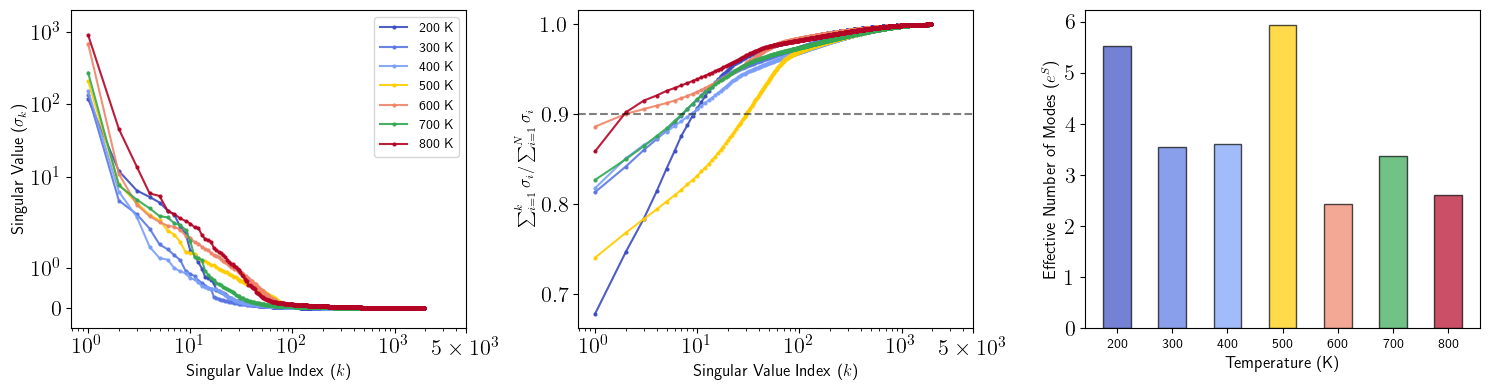

In [11]:
covariance_matrix_200_element_framework = covariance_matrix_200K[np.ix_(element_indices, framework_indices)]
covariance_matrix_300_element_framework = covariance_matrix_300K[np.ix_(element_indices, framework_indices)]
covariance_matrix_400_element_framework = covariance_matrix_400K[np.ix_(element_indices, framework_indices)]
covariance_matrix_500_element_framework = covariance_matrix_500K[np.ix_(element_indices, framework_indices)]
covariance_matrix_600_element_framework = covariance_matrix_600K[np.ix_(element_indices, framework_indices)]
covariance_matrix_700_element_framework = covariance_matrix_700K[np.ix_(element_indices, framework_indices)]
covariance_matrix_800_element_framework = covariance_matrix_800K[np.ix_(element_indices, framework_indices)]
u_200, s_200, vt_200 = np.linalg.svd(covariance_matrix_200_element_framework)
u_300, s_300, vt_300 = np.linalg.svd(covariance_matrix_300_element_framework)
u_400, s_400, vt_400 = np.linalg.svd(covariance_matrix_400_element_framework)
u_500, s_500, vt_500 = np.linalg.svd(covariance_matrix_500_element_framework)
u_600, s_600, vt_600 = np.linalg.svd(covariance_matrix_600_element_framework)
u_700, s_700, vt_700 = np.linalg.svd(covariance_matrix_700_element_framework)
u_800, s_800, vt_800 = np.linalg.svd(covariance_matrix_800_element_framework)

framework_index_map = {i: j for j, i in enumerate(framework_indices)}

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# plot the normalized singular values for each temperature, using a different color for each temperature

ax[0].plot([i + 1 for i in range(len(s_200))], s_200, "o-", c=color_200K, label="200 K", alpha=0.9, markersize=2)
ax[0].plot([i + 1 for i in range(len(s_300))], s_300, "o-", c=color_300K, label="300 K", alpha=0.9, markersize=2)
ax[0].plot([i + 1 for i in range(len(s_400))], s_400, "o-", c=color_400K, label="400 K", alpha=0.9, markersize=2)
ax[0].plot([i + 1 for i in range(len(s_500))], s_500, "o-", c=color_500K, label="500 K", alpha=0.9, markersize=2)
ax[0].plot([i + 1 for i in range(len(s_600))], s_600, "o-", c=color_600K, label="600 K", alpha=0.9, markersize=2)
ax[0].plot([i + 1 for i in range(len(s_700))], s_700, "o-", c=color_700K, label="700 K", alpha=0.9, markersize=2)
ax[0].plot([i + 1 for i in range(len(s_800))], s_800, "o-", c=color_800K, label="800 K", alpha=0.9, markersize=2)
ax[0].set_xscale("log")
ax[0].set_yscale("symlog")
ax[0].set_ylim(-0.5, 2000)
ax[0].set_xlabel("Singular Value Index ($k$)", fontsize=12)
ax[0].set_ylabel("Singular Value ($\\sigma_k$)", fontsize=12)
ax[0].set_xticks([1, 10, 100, 1000, 5000])
ax[0].set_xticklabels(["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$5\\times10^3$"])
ax[0].legend(fontsize=10)

# cumulative sum of singular values normalized by the total sum of singular values
ax[1].plot([i + 1 for i in range(len(s_200))], [np.sum(s_200[: i + 1]) / np.sum(s_200) for i in range(len(s_200))], "o-", c=color_200K, label="200 K", alpha=0.9, markersize=2)
ax[1].plot([i + 1 for i in range(len(s_300))], [np.sum(s_300[: i + 1]) / np.sum(s_300) for i in range(len(s_300))], "o-", c=color_300K, label="300 K", alpha=0.9, markersize=2)
ax[1].plot([i + 1 for i in range(len(s_400))], [np.sum(s_400[: i + 1]) / np.sum(s_400) for i in range(len(s_400))], "o-", c=color_400K, label="400 K", alpha=0.9, markersize=2)
ax[1].plot([i + 1 for i in range(len(s_500))], [np.sum(s_500[: i + 1]) / np.sum(s_500) for i in range(len(s_500))], "o-", c=color_500K, label="500 K", alpha=0.9, markersize=2)
ax[1].plot([i + 1 for i in range(len(s_600))], [np.sum(s_600[: i + 1]) / np.sum(s_600) for i in range(len(s_600))], "o-", c=color_600K, label="600 K", alpha=0.9, markersize=2)
ax[1].plot([i + 1 for i in range(len(s_700))], [np.sum(s_700[: i + 1]) / np.sum(s_700) for i in range(len(s_700))], "o-", c=color_700K, label="700 K", alpha=0.9, markersize=2)
ax[1].plot([i + 1 for i in range(len(s_800))], [np.sum(s_800[: i + 1]) / np.sum(s_800) for i in range(len(s_800))], "o-", c=color_800K, label="800 K", alpha=0.9, markersize=2)
ax[1].set_xscale("log")
ax[1].set_xticks([1, 10, 100, 1000, 5000])
ax[1].set_xticklabels(["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$5\\times10^3$"])
ax[1].axhline(0.9, c="k", ls="--", alpha=0.5)

ax[1].set_xlabel("Singular Value Index ($k$)", fontsize=12)
ax[1].set_ylabel("$\\sum_{i=1}^k \\sigma_i / \\sum_{i=1}^N \\sigma_i$", fontsize=12)
# ax[1].legend(fontsize=10)

prob_200 = [s_200[i]/np.sum(s_200) for i in range(len(s_200))]
prob_300 = [s_300[i]/np.sum(s_300) for i in range(len(s_300))]
prob_400 = [s_400[i]/np.sum(s_400) for i in range(len(s_400))]
prob_500 = [s_500[i]/np.sum(s_500) for i in range(len(s_500))]
prob_600 = [s_600[i]/np.sum(s_600) for i in range(len(s_600))]
prob_700 = [s_700[i]/np.sum(s_700) for i in range(len(s_700))]
prob_800 = [s_800[i]/np.sum(s_800) for i in range(len(s_800))]

entropy_200 = -np.sum([p * np.log(p) for p in prob_200])
entropy_300 = -np.sum([p * np.log(p) for p in prob_300])
entropy_400 = -np.sum([p * np.log(p) for p in prob_400])
entropy_500 = -np.sum([p * np.log(p) for p in prob_500])
entropy_600 = -np.sum([p * np.log(p) for p in prob_600])
entropy_700 = -np.sum([p * np.log(p) for p in prob_700])
entropy_800 = -np.sum([p * np.log(p) for p  in prob_800])   

effective_modes_200 = np.exp(entropy_200)
effective_modes_300 = np.exp(entropy_300)
effective_modes_400 = np.exp(entropy_400)
effective_modes_500 = np.exp(entropy_500)
effective_modes_600 = np.exp(entropy_600)
effective_modes_700 = np.exp(entropy_700)
effective_modes_800 = np.exp(entropy_800)   

ax[2].bar([1,2,3,4,5,6,7],[effective_modes_200, effective_modes_300, effective_modes_400, effective_modes_500, effective_modes_600, effective_modes_700, effective_modes_800], color=[color_200K, color_300K, color_400K, color_500K, color_600K, color_700K, color_800K], alpha=0.7, width=0.5, edgecolor="k")
ax[2].set_xticks([1,2,3,4,5,6,7], labels=["200", "300", "400", "500", "600", "700", "800"], fontsize=10)
ax[2].set_ylabel("Effective Number of Modes ($e^S$)", fontsize=12)
ax[2].set_xlabel("Temperature (K)", fontsize=12)    

plt.tight_layout()
plt.savefig(
    "/Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion-documents/nve_md_essential_dynamics_analysis_Li_framework_svd.pdf",
    bbox_inches="tight",
)
plt.show()

number of P atoms:  108
number of S atoms:  540
number of Cl atoms:  108


Text(702.0, 50, 'Cl')

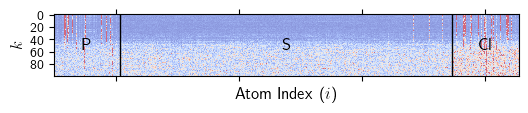

In [7]:
P_indices = [i for i, symbol in enumerate(input_atom_order) if symbol == 'P']
S_indices = [i for i, symbol in enumerate(input_atom_order) if symbol == 'S']
Cl_indices = [i for i, symbol in enumerate(input_atom_order) if symbol == 'Cl']

Li_indices = [i for i, symbol in enumerate(input_atom_order) if symbol == 'Li']
# for the P, S and Cl indicies, we need to shift there values by removing the Li indices from the list of all indices, since the V matrix is only for the framework atoms
P_indices = [i - sum([1 for li in Li_indices if li < i]) for i in P_indices]
S_indices = [i - sum([1 for li in Li_indices if li < i]) for i in S_indices]
Cl_indices = [i - sum([1 for li in Li_indices if li < i]) for i in Cl_indices]

# for the V matrix, we combine the x, y, z components of each atom into a single vector by taking the norm of the 3 components, and then we plot the V matrix as a heatmap, with the x-axis being the atom index and the y-axis being the singular value index
v_transposed = vt_800.T
v_condensed = np.zeros((v_transposed.shape[0]//3, v_transposed.shape[1]))
for i in range(v_transposed.shape[0]//3):
    v_condensed[i,:] = np.linalg.norm(v_transposed[3*i:3*i+3,:], axis=0)    

# reorder the rows of v_condensed so that the P, S, and Cl atoms are grouped together
print("number of P atoms: ", len(P_indices))
print("number of S atoms: ", len(S_indices))
print("number of Cl atoms: ", len(Cl_indices))

v_condensed_reordered = np.zeros_like(v_condensed)
for i, idx in enumerate(P_indices):
    v_condensed_reordered[i,:] = v_condensed[idx,:]

for i, idx in enumerate(S_indices):
    v_condensed_reordered[len(P_indices)+i,:] = v_condensed[idx,:]

for i, idx in enumerate(Cl_indices):
    v_condensed_reordered[len(P_indices)+len(S_indices)+i,:] = v_condensed[idx,:]


import matplotlib
fig, ax = plt.subplots(figsize=(6, 4))
im=ax.matshow(v_condensed_reordered.T[:100,:], cmap="coolwarm", vmin=0, vmax=0.08, alpha=0.6)
# add lines to separate the P, S, and Cl atoms
ax.axvline(len(P_indices)-0.5, color="k", linewidth=1)
ax.axvline(len(P_indices)+len(S_indices)-0.5, color="k", linewidth=1)
ax.set_yticks([0, 20, 40, 60, 80])
ax.set_yticklabels([0, 20, 40, 60, 80], fontsize=10)

#ax.set_yticks([])

ax.set_xticks([100,300,500,700])
#ax.set_xticklabels([100,300,500,700], fontsize=10)
ax.set_xticklabels([])
ax.set_ylabel("$k$", fontsize=12)
ax.set_xlabel("Atom Index ($i$)", fontsize=12)
ax.text(len(P_indices)/2, 50, "P", fontsize=12, color="k", ha="center", va="center")
ax.text(len(P_indices)+len(S_indices)/2, 50, "S", fontsize=12, color="k", ha="center", va="center")
ax.text(len(P_indices)+len(S_indices)+len(Cl_indices)/2, 50, "Cl", fontsize=12, color="k", ha="center", va="center")

#cbar = fig.colorbar(im, ax=ax, pad=0.1,fraction=0.05, aspect=20)
#cbar.set_label("Magnitude of Singular Vector on Each Atom", fontsize=10)
#cbar.ax.tick_params(labelsize=10)

Plotting the eigenvectors to see how the distributions of the matrix elements $\mathbf{v}_{k,n}$ looks like.

In [136]:
# need to regroup the entries in the eigenvectors according to the atomic species, so that we can visualise the contribution of each atomic species to each eigenvector. The current order of the entries in the eigenvectors is according to the order of the atoms in the equilibrium structure, which is Li, P, S, Cl. We want to reorder the entries so that they are grouped by atomic species, i.e. all Li entries first, then all P entries, then all S entries, and finally all Cl entries.
input_atom_order = averaged_structure.get_chemical_symbols()
input_atom_oder_dict = {i: symbol for i, symbol in enumerate(input_atom_order)}
reordered_indicies = []
for symbols in ['Li', 'S', 'P', 'Cl']:
    indices = [i for i, symbol in input_atom_oder_dict.items() if symbol == symbols]
    expanded_indices = list(np.array([[3*i, 3*i+1, 3*i+2] for i in indices]).reshape(-1))
    
    reordered_indicies += expanded_indices
    print(symbols, len(reordered_indicies))
   

reordered_eigenvectors_200K = np.zeros_like(eigenvectors_200K)
reordered_eigenvectors_600K = np.zeros_like(eigenvectors_600K)

for i in range(eigenvectors_200K.shape[0]):
    reordered_eigenvectors_200K[i] = eigenvectors_200K[i][reordered_indicies]
    reordered_eigenvectors_600K[i] = eigenvectors_600K[i][reordered_indicies]

import matplotlib.colors as colors

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
cax=ax[0].matshow(reordered_eigenvectors_200K,cmap='RdBu_r',vmin=-0.01, vmax=0.01)
#ax.tick_params(top=False, labeltop=False) 
plt.setp(ax[0].get_xticklabels(), rotation='vertical', ha='right')

ax[0].set_ylabel('Eigenvector Index')
ax[0].set_xlabel('Atomic Component Index')
fig.colorbar(cax,shrink=0.6)

cax=ax[1].matshow(reordered_eigenvectors_600K,cmap='RdBu_r',vmin=-0.01, vmax=0.01)
#ax.tick_params(top=False, labeltop=False) 
plt.setp(ax[1].get_xticklabels(), rotation='vertical', ha='right')

ax[1].set_ylabel('Eigenvector Index')
ax[1].set_xlabel('Atomic Component Index')
fig.colorbar(cax,shrink=0.6)
plt.tight_layout()
plt.show()

NameError: name 'averaged_structure' is not defined

In [ ]:
xs_200K=[]
ys_200K=[]
xs_600K=[]
ys_600K=[]  
for i in _progress(range(0,len(atomic_displacements),10), desc="Projecting trajectory data", leave=False):
    projection_1_200K = np.dot(atomic_displacements[i], eigenvectors_200K[:, 0])
    projection_2_200K = np.dot(atomic_displacements[i], eigenvectors_200K[:, second_index])
    xs_200K.append(projection_1_200K)
    ys_200K.append(projection_2_200K)

    projection_1_600K = np.dot(atomic_displacements[i], eigenvectors_600K[:, 0])
    projection_2_600K = np.dot(atomic_displacements[i], eigenvectors_600K[:, second_index])
    xs_600K.append(projection_1_600K)
    ys_600K.append(projection_2_600K)

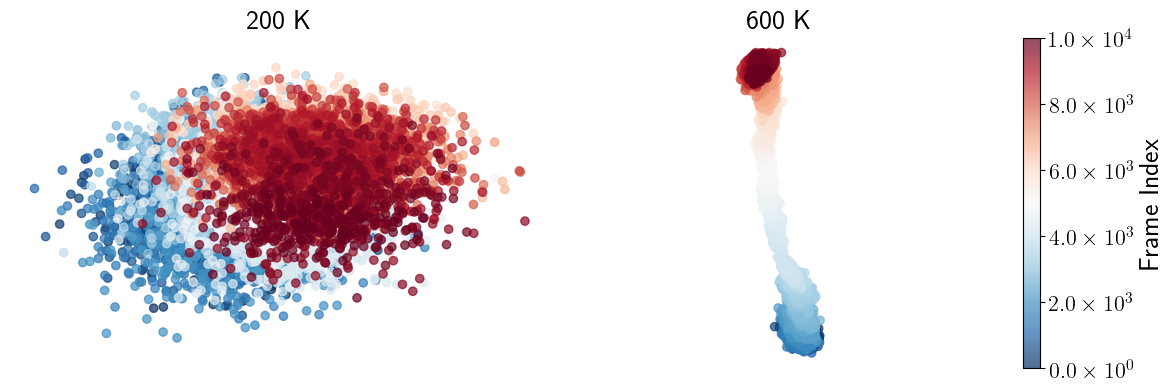

In [ ]:
import matplotlib.colors as colors
import matplotlib.ticker as ticker

def fmt(x, pos):
    a, b = '{:.1e}'.format(x).split('e')
    b = int(b)
    return r'${} \times 10^{{{}}}$'.format(a, b)


seq = np.arange(len(xs_200K))
#seq = system_energies
plt.subplots(1, 2, figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(xs_200K, ys_200K, c=seq, cmap='RdBu_r', norm=colors.Normalize(vmin=min(seq), vmax=max(seq)), alpha=0.7)
#plt.colorbar(label='Frame Index')
plt.title('200 K')
plt.axis('equal')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.scatter(xs_600K, ys_600K, c=seq, cmap='RdBu_r', norm=colors.Normalize(vmin=min(seq), vmax=max(seq)), alpha=0.7)
plt.colorbar(label='Frame Index',format=ticker.FuncFormatter(fmt))
plt.title('600 K')
plt.axis('equal')
plt.axis('off')

plt.tight_layout()

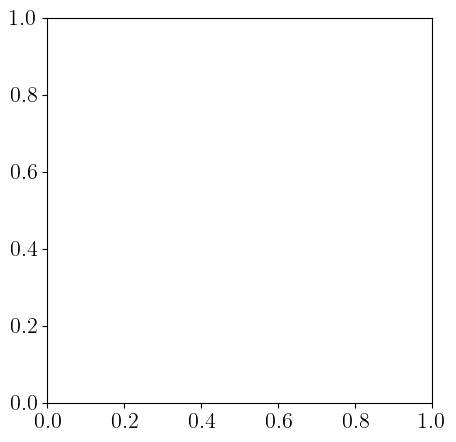

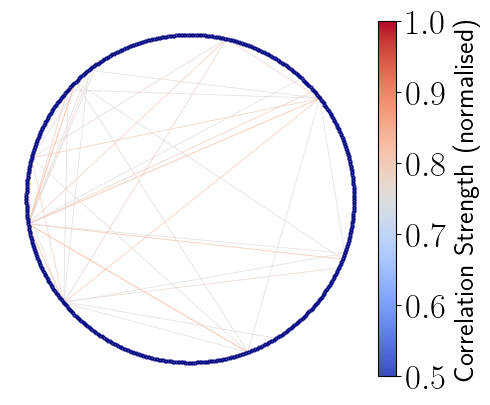

In [11]:
def reformat_correlation_matrix(corr_matrix):
    # Number of degrees of freedom (3N for N atoms)
    n_dof = corr_matrix.shape[0]
    n_atoms = n_dof // 3

    corr_vales = np.zeros((n_atoms, n_atoms))

    for k in range(0, n_atoms, 1):
        for j in range(0, n_atoms, 1):
            corr_value = 0
            for p in [3*k, 3*k+1, 3*k+2]:  # Sample every 200th point for clarity
                for q in [3*j, 3*j+1, 3*j+2]:
                    corr_value += np.abs(corr_matrix[p, q])**2

            corr_value = np.sqrt(corr_value)
            corr_vales[k, j] = corr_value
    return corr_vales

# Circular correlation plot (chord diagram) for covariance matrix
# Extract off-diagonal elements and visualize as lines on a circle

fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(aspect='equal'))

correlation_matrix = covariance_matrix_600K_element 
n_atoms = correlation_matrix.shape[0] // 3
corr_vales = reformat_correlation_matrix(correlation_matrix)

# Place points on a circle
angles = np.linspace(0, 2*np.pi, n_atoms, endpoint=False)
radius = 1.0
x_pos = radius * np.cos(angles)
y_pos = radius * np.sin(angles)

threshold = 0.5
line_width_scale = 1.0
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(aspect="equal"))

for k in range(0,n_atoms,1):
    for j in range(0,n_atoms,1):
        corr_value = corr_vales[k, j]
        relative_corr = (corr_value - np.min(corr_vales)) / (np.max(corr_vales) - np.min(corr_vales))

        if relative_corr > threshold:
            
            # Line width proportional to correlation strength
            line_width = line_width_scale * relative_corr

            # Normalize correlation for color mapping
            color_val = relative_corr  # Already normalized to [0, 1]

            # Draw line between points
            ax.plot(
                    [x_pos[k], x_pos[j]], 
                    [y_pos[k], y_pos[j]], 
                    color=plt.cm.coolwarm(color_val),
                    linewidth=line_width,
                    alpha=0.5,
                    zorder=1
            )


# Draw points on circle
ax.scatter(x_pos, y_pos, s=1, c='steelblue', edgecolors='navy', linewidth=2, zorder=2, alpha=0.8)

# ax.set_xlim(-1.5, 1.5)
# ax.set_ylim(-1.5, 1.5)
ax.set_aspect('equal')
ax.axis('off')

# Add colorbar
sm = plt.cm.ScalarMappable(cmap=plt.cm.coolwarm, 
                           norm=matplotlib.colors.Normalize(vmin=threshold, vmax=1.0))
# sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02, fraction=0.046, label='Correlation Strength (normalised)')
cbar.ax.tick_params(labelsize=25)
plt.tight_layout()
plt.show()

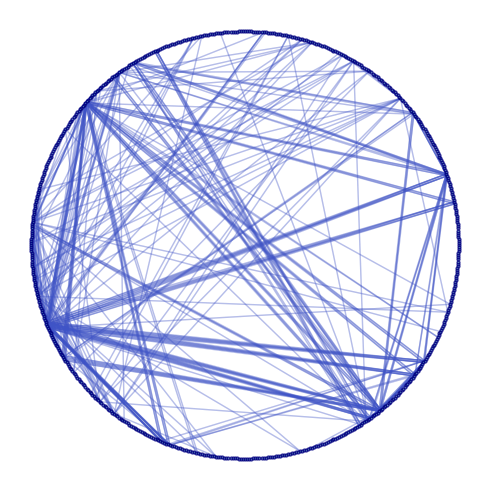

In [62]:
import math
cov_mat_200K_element = reformat_correlation_matrix(covariance_matrix_200K_element)
cov_mat_300K_element = reformat_correlation_matrix(covariance_matrix_300K_element)
cov_mat_400K_element = reformat_correlation_matrix(covariance_matrix_400K_element)
cov_mat_500K_element = reformat_correlation_matrix(covariance_matrix_500K_element)
cov_mat_600K_element = reformat_correlation_matrix(covariance_matrix_600K_element)
cov_mat_800K_element = reformat_correlation_matrix(covariance_matrix_800K_element)

# find the min and max values across all matrices for consistent color scaling
min_val = min(np.min(cov_mat_200K_element), np.min(cov_mat_300K_element), np.min(cov_mat_400K_element), np.min(cov_mat_500K_element), np.min(cov_mat_600K_element), np.min(cov_mat_800K_element))
max_val = max(np.max(cov_mat_200K_element), np.max(cov_mat_300K_element), np.max(cov_mat_400K_element), np.max(cov_mat_500K_element), np.max(cov_mat_600K_element), np.max(cov_mat_800K_element))

cov_mat = cov_mat_200K_element
n_atoms = cov_mat.shape[0]

# Place points on a circle
angles = np.linspace(0, 2 * np.pi, n_atoms, endpoint=False)
radius = 1.0
x_pos = radius * np.cos(angles)
y_pos = radius * np.sin(angles)
threshold = 0.5
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(aspect="equal"))

#get the percentile of the correlation values to use as a threshold for drawing lines
threshold = np.percentile(cov_mat, 99.75)

for k in range(0, n_atoms, 1):
    for j in range(0, n_atoms, 1):
        corr_value = cov_mat[k, j]

        #relative_corr = (corr_value - np.min(cov_mat)) / (np.max(cov_mat) - np.min(cov_mat))

        if corr_value > threshold:
            corr_value = np.abs(cov_mat[k, j])
            plt.plot(
                [x_pos[k], x_pos[j]],
                [y_pos[k], y_pos[j]],
                color=plt.cm.coolwarm(math.sin(corr_value/max_val*math.pi/2)),
                linewidth=1,
                alpha=min(1,0.2+corr_value/max_val))

# Draw points on circle
ax.scatter(x_pos, y_pos, s=1, c="steelblue", edgecolors="navy", linewidth=2, zorder=2, alpha=0.8)

# ax.set_xlim(-1.5, 1.5)
# ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.axis("off")

# Add colorbar
#import matplotlib.colors as mcolors
#sm = plt.cm.ScalarMappable(cmap=plt.cm.coolwarm, norm=mcolors.Normalize(vmin=min_val, vmax=max_val))
#cbar = plt.colorbar(sm, ax=ax, pad=0.02, fraction=0.046, label="Correlation Strength")
#cbar.ax.tick_params(labelsize=25)
plt.tight_layout()
plt.show()

(648, 756)


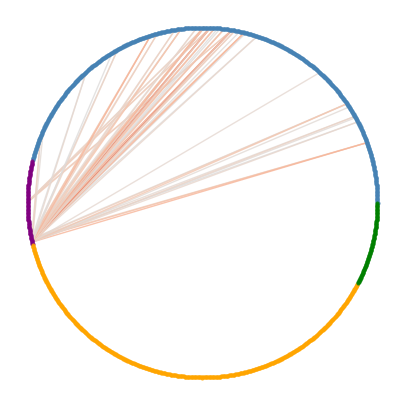

In [ ]:
__covariance_matrix = covariance_matrix_200K
# reorder the rows of covariance_matrix_element_framework so that the P, S, and Cl atoms are grouped together and Li atoms comes first
covariance_matrix_element_framework_reordered = np.zeros([len(Li_indices), len(P_indices)+len(S_indices)+len(Cl_indices)])

for i, Li_idx in enumerate(Li_indices):
    for p, P_idx in enumerate(P_indices):
        entry = 0.0
        for a in range(3):
            for b in range(3):
                entry += __covariance_matrix[3 * Li_idx + a, 3 * P_idx + b] ** 2
        covariance_matrix_element_framework_reordered[i, p] = np.sqrt(entry)    

    for s, S_idx in enumerate(S_indices):
        entry = 0.0
        for a in range(3):
            for b in range(3):
                entry += __covariance_matrix[3 * Li_idx + a, 3 * S_idx + b] ** 2
        covariance_matrix_element_framework_reordered[i, len(P_indices)+s] = np.sqrt(entry)

    for c, Cl_idx in enumerate(Cl_indices):
        entry = 0.0
        for a in range(3):
            for b in range(3):
                entry += __covariance_matrix[3 * Li_idx + a, 3 * Cl_idx + b] ** 2
        covariance_matrix_element_framework_reordered[i, len(P_indices) + len(S_indices) + c] = np.sqrt(entry)

covariance_matrix_element_framework_reordered = np.abs(covariance_matrix_element_framework_reordered)
max_value = np.max(covariance_matrix_element_framework_reordered)

# normalize the covariance matrix so that the maximum value is 1
# covariance_matrix_element_framework_reordered
print(covariance_matrix_element_framework_reordered.shape)
natoms = len(Li_indices)+len(P_indices)+len(S_indices)+len(Cl_indices)

angles = np.linspace(0, 2 * np.pi, natoms, endpoint=False)
radius = 1.0

x_pos = radius * np.cos(angles)
y_pos = radius * np.sin(angles)

threshold = 0.5
line_width_scale = 0.5

fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(aspect="equal"))

for i in range(len(Li_indices)):
    j = len(Li_indices) 
    while j < len(P_indices) + len(S_indices) + len(Cl_indices):
        corr_value = covariance_matrix_element_framework_reordered[i, j]
        relative_corr = (corr_value - np.min(covariance_matrix_element_framework_reordered)) / (np.max(covariance_matrix_element_framework_reordered) - np.min(covariance_matrix_element_framework_reordered))
        if relative_corr > threshold:
            line_width = line_width_scale * corr_value
            color_val = corr_value
            ax.plot(
                [x_pos[i], x_pos[j]], 
                [y_pos[i], y_pos[j]], 
                color=plt.cm.coolwarm(relative_corr),
                linewidth=1,
                alpha=min(1,0.2+corr_value/max_val),
                zorder=1
            )
        j+=1

ax.scatter(x_pos[:len(Li_indices)], y_pos[:len(Li_indices)], s=1, c="steelblue", edgecolors=None, linewidth=2, zorder=2, alpha=0.8)
ax.scatter(x_pos[len(Li_indices)+1:len(Li_indices)+1+len(P_indices)],y_pos[len(Li_indices)+1:len(Li_indices)+1+len(P_indices)], s=1, c="purple", edgecolors=None, linewidth=2, zorder=2, alpha=0.8)
ax.scatter(x_pos[len(Li_indices)+1+len(P_indices):len(Li_indices)+1+len(P_indices)+len(S_indices)], y_pos[len(Li_indices)+1+len(P_indices):len(Li_indices)+1+len(P_indices)+len(S_indices)], s=1, c="orange", edgecolors=None, linewidth=2, zorder=2, alpha=0.8)
ax.scatter(x_pos[len(Li_indices)+1+len(P_indices)+len(S_indices):], y_pos[len(Li_indices)+1+len(P_indices)+len(S_indices):], s=1, c="green", edgecolors=None, linewidth=2, zorder=2, alpha=0.8)

ax.set_aspect("equal")
ax.axis("off")


# Add colorbar
#sm = plt.cm.ScalarMappable(cmap=plt.cm.coolwarm, norm=plt.Normalize(vmin=threshold, vmax=1.0))
#sm.set_array([])
#cbar = plt.colorbar(sm, ax=ax, pad=0.02, fraction=0.046, label="Correlation Strength (normalised)")
#cbar.ax.tick_params(labelsize=25)

plt.show()

min_val:  0.00025873723262868616
max_val:  41.2277419104513
(648, 756)


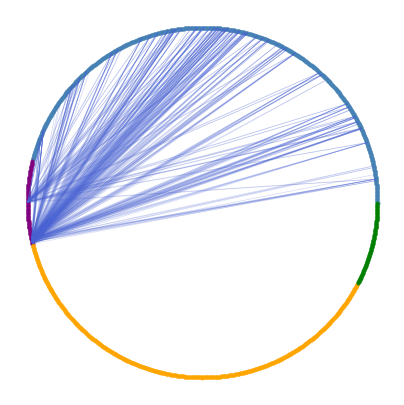

In [71]:
def reformat_off_diag_correlation_matrix(corr_matrix):
    covariance_matrix_element_framework_reordered = np.zeros([len(Li_indices), len(P_indices) + len(S_indices) + len(Cl_indices)])

    for i, Li_idx in enumerate(Li_indices):
        for p, P_idx in enumerate(P_indices):
            entry = 0.0
            for a in range(3):
                for b in range(3):
                    entry += corr_matrix[3 * Li_idx + a, 3 * P_idx + b] ** 2
            covariance_matrix_element_framework_reordered[i, p] = np.sqrt(entry)

        for s, S_idx in enumerate(S_indices):
            entry = 0.0
            for a in range(3):
                for b in range(3):
                    entry += corr_matrix[3 * Li_idx + a, 3 * S_idx + b] ** 2
            covariance_matrix_element_framework_reordered[i, len(P_indices) + s] = np.sqrt(entry)

        for c, Cl_idx in enumerate(Cl_indices):
            entry = 0.0
            for a in range(3):
                for b in range(3):
                    entry += corr_matrix[3 * Li_idx + a, 3 * Cl_idx + b] ** 2
            covariance_matrix_element_framework_reordered[i, len(P_indices) + len(S_indices) + c] = np.sqrt(entry)
    covariance_matrix_element_framework_reordered = np.abs(covariance_matrix_element_framework_reordered)
    return covariance_matrix_element_framework_reordered

cov_element_framework_200K = reformat_off_diag_correlation_matrix(covariance_matrix_200K)
cov_element_framework_300K = reformat_off_diag_correlation_matrix(covariance_matrix_300K)
cov_element_framework_400K = reformat_off_diag_correlation_matrix(covariance_matrix_400K)
cov_element_framework_500K = reformat_off_diag_correlation_matrix(covariance_matrix_500K)
cov_element_framework_600K = reformat_off_diag_correlation_matrix(covariance_matrix_600K)
cov_element_framework_800K = reformat_off_diag_correlation_matrix(covariance_matrix_800K)   

min_val = min(np.min(cov_element_framework_200K), np.min(cov_element_framework_300K), np.min(cov_element_framework_400K), np.min(cov_element_framework_500K), np.min(cov_element_framework_600K), np.min(cov_element_framework_800K))
max_val = max(np.max(cov_element_framework_200K), np.max(cov_element_framework_300K), np.max(cov_element_framework_400K), np.max(cov_element_framework_500K), np.max(cov_element_framework_600K), np.max(cov_element_framework_800K))
print("min_val: ", min_val)
print("max_val: ", max_val)
# normalize the covariance matrix so that the maximum value is 1
# covariance_matrix_element_framework_reordered
covariance_matrix_element_framework_reordered = cov_element_framework_200K

print(covariance_matrix_element_framework_reordered.shape)
natoms = len(Li_indices) + len(P_indices) + len(S_indices) + len(Cl_indices)

angles = np.linspace(0, 2 * np.pi, natoms, endpoint=False)
radius = 1.0

x_pos = radius * np.cos(angles)
y_pos = radius * np.sin(angles)

threshold = np.percentile(covariance_matrix_element_framework_reordered, 99.5)
line_width_scale = 0.5

import matplotlib.pyplot as pplt
fig, ax = pplt.subplots(figsize=(5, 5), subplot_kw=dict(aspect="equal"))

ax.scatter(x_pos[: len(Li_indices)], y_pos[: len(Li_indices)], s=1, c="steelblue", edgecolors=None, linewidth=2, alpha=0.8)
ax.scatter(
    x_pos[len(Li_indices) + 1 : len(Li_indices) + 1 + len(P_indices)],
    y_pos[len(Li_indices) + 1 : len(Li_indices) + 1 + len(P_indices)],
    s=1,
    c="purple",
    edgecolors=None,
    linewidth=2,
    alpha=0.8,
)
ax.scatter(
    x_pos[len(Li_indices) + 1 + len(P_indices) : len(Li_indices) + 1 + len(P_indices) + len(S_indices)],
    y_pos[len(Li_indices) + 1 + len(P_indices) : len(Li_indices) + 1 + len(P_indices) + len(S_indices)],
    s=1,
    c="orange",
    edgecolors=None,
    linewidth=2,
    alpha=0.8,
)
ax.scatter(
    x_pos[len(Li_indices) + 1 + len(P_indices) + len(S_indices) :],
    y_pos[len(Li_indices) + 1 + len(P_indices) + len(S_indices) :],
    s=1,
    c="green",
    edgecolors=None,
    linewidth=2,
    alpha=0.8,
)

for k in range(len(Li_indices)):
    for j in range(len(Li_indices), len(P_indices) + len(S_indices) + len(Cl_indices)):
        corr_value = covariance_matrix_element_framework_reordered[k, j]

        if corr_value > threshold:
            corr_value = np.abs(covariance_matrix_element_framework_reordered[k, j])
            plt.plot([x_pos[k], x_pos[j]], [y_pos[k], y_pos[j]], color=plt.cm.coolwarm(math.sin(corr_value/max_val*math.pi/2)), linewidth=0.5, alpha=min(1,0.2+corr_value/max_val))

ax.set_aspect("equal")
ax.axis("off")
# Add colorbar
#import matplotlib.colors as mcolors
#sm = plt.cm.ScalarMappable(cmap=plt.cm.coolwarm, norm=mcolors.Normalize(vmin=min_val, vmax=max_val))
#cbar = plt.colorbar(sm, ax=ax, pad=0.02, fraction=0.046, label="Correlation Strength")
#cbar.ax.tick_params(labelsize=25)

plt.show()